Actual    Predicted
2.0        2.01
3.0        2.94
4.0        4.03
5.0        5.06
6.0        5.95


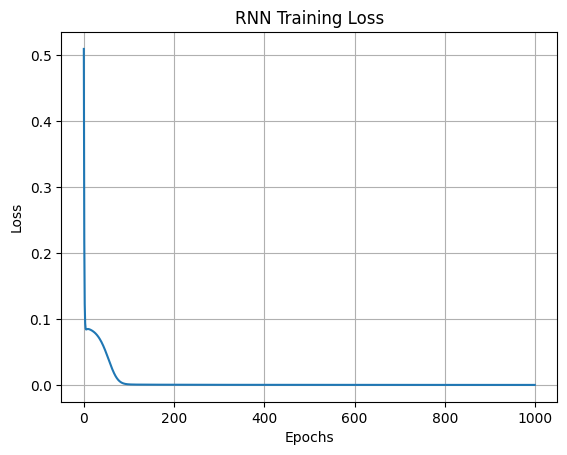

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Input data
X = np.array([1, 2, 3, 4, 5], dtype=float) / 5
Y = np.array([2, 3, 4, 5, 6], dtype=float) / 5

# 2. Initialize weights
np.random.seed(42)
Wx = np.random.randn() * 0.1
Wh = np.random.randn() * 0.1
Wy = np.random.randn() * 0.1
bh = 0.0
by = 0.0

lr = 0.05
losses = []

# 3. Train RNN
for epoch in range(1000):
    h = 0.0
    total_loss = 0.0

    for x, target in zip(X, Y):
        h_prev = h
        h = np.tanh(Wx * x + Wh * h_prev + bh)
        output = Wy * h + by

        #error calculate  
        error = output - target
        total_loss += error ** 2

        # Calculate gradients
        dy = 2 * error
        dh = dy * Wy * (1 - h ** 2)

        # Update weights
        Wy -= lr * dy * h       Wx -= lr * dh * x
        by -= lr * dy           wh -= lr * dh * h_prev
        Wx -= lr * dh * x       wy -= lr * dy * h 
        Wh -= lr * dh * h_prev  bh -= lr * dh
        bh -= lr * dh           by -= lr * dy 

    losses.append(total_loss / len(X))

# 4. Test RNN
h = 0.0
print("Actual    Predicted")

for x, target in zip(X, Y):
    h = np.tanh(Wx * x + Wh * h + bh)
    prediction = Wy * h + by
    print(round(target * 5, 2),"      ", round(prediction * 5, 2))

# 5. Plot loss
plt.plot(losses)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("RNN Training Loss")
plt.grid(True)
plt.show()